# Analysis of results after stage 2

Ran prolog generation on Article 11(1) for GPT Astra; seed 1-10

In [ ]:
%pip install numpy matplotlib pandas seaborn

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import os

## 1. Answer agreement

In [4]:
df_ans_agr = pd.read_csv("./out_paragraphs/csv/answer_agreement.csv", delimiter=",")
df_ans_agr.head()

,text,adapter,model_a,seed_a,model_b,seed_b,same_model,answer_agreement,passed_a,passed_b
0,art_11_par_1,llm,astra,1,astra,2,True,0.727,5,8
1,art_11_par_1,llm,astra,1,astra,3,True,1.000,5,5
2,art_11_par_1,llm,astra,1,astra,4,True,0.970,5,6
3,art_11_par_1,llm,astra,1,astra,5,True,0.545,5,1
4,art_11_par_1,llm,astra,1,astra,6,True,0.667,5,10


In [7]:
df_ans_agr.shape

(739, 10)

In [8]:
df_astra = df_ans_agr[df_ans_agr['model_a'].isin(["astra", "astra-medium"]) & df_ans_agr['model_b'].isin(["astra", "astra-medium"])]
df_astra.shape

(205, 10)

In [14]:
agreement_mean_hand_adapter = df_astra[df_astra["adapter"] == "hand"]["answer_agreement"].mean()
print(f"Mean agreement for hand adapter: {agreement_mean_hand_adapter}")
print(f"SD for hand adapter: {df_astra[df_astra['adapter'] == 'hand']['answer_agreement'].std()}")
print(f"Number of cases for hand adapter: {df_astra[df_astra['adapter'] == 'hand'].shape[0]}")

agreement_mean_lmm_adapter = df_astra[df_astra["adapter"] == "llm"]["answer_agreement"].mean()
print(f"Mean agreement for llm adapter: {agreement_mean_lmm_adapter}")
print(f"SD for llm adapter: {df_astra[df_astra['adapter'] == 'llm']['answer_agreement'].std()}")
print(f"Number of cases for llm adapter: {df_astra[df_astra['adapter'] == 'llm'].shape[0]}")

Mean agreement for hand adapter: 0.8020666666666666
SD for hand adapter: 0.14382999223620455
Number of cases for hand adapter: 15
Mean agreement for llm adapter: 0.7564263157894737
SD for llm adapter: 0.1713800268103882
Number of cases for llm adapter: 190


<Axes: xlabel='answer_agreement', ylabel='passed_a'>

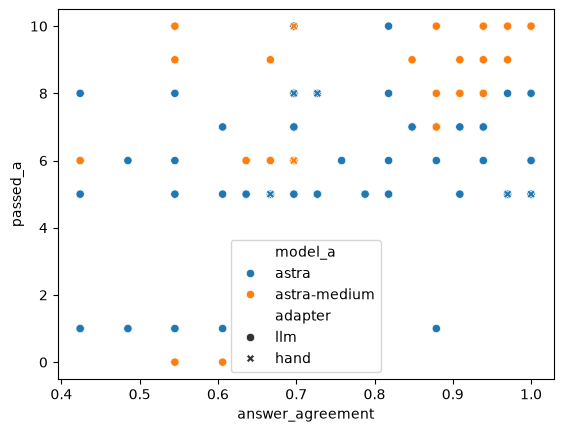

In [15]:
sns.scatterplot(data=df_astra, x='answer_agreement', y='passed_a', hue='model_a', style='adapter')

<Axes: xlabel='answer_agreement', ylabel='passed_b'>

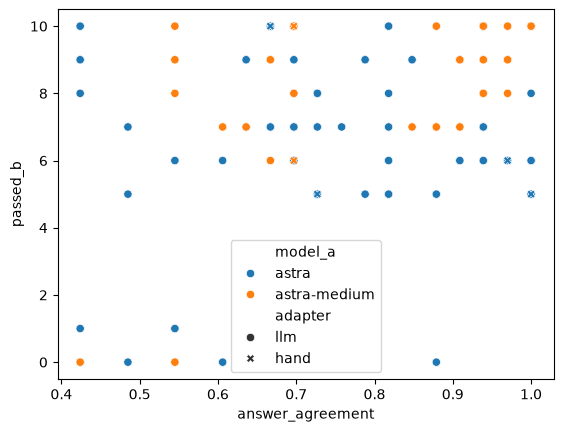

In [16]:
sns.scatterplot(data=df_astra, x='answer_agreement', y='passed_b', hue='model_a', style='adapter')

What we can maybe deduce is the fact that IF THE ANSWER AGREEMENT IS HIGH, THERE IS A BETTER CHANCE MORE SCENARIOS WERE PASSED RATHER THAN LESS (can be seen by the empty lower right corner in both plots).

## 2. Scenario queries

In [17]:
df = pd.read_csv("./out_paragraphs/csv/scenario_queries.csv", delimiter=",")
df.shape

(1551, 13)

In [18]:
df_min = df[df["model"] == "astra"]
df_med = df[df["model"] == "astra-medium"]

In [19]:
df["verdict"].value_counts()

verdict
unanswerable      741
correct           517
missed            179
false_positive    114
Name: count, dtype: int64

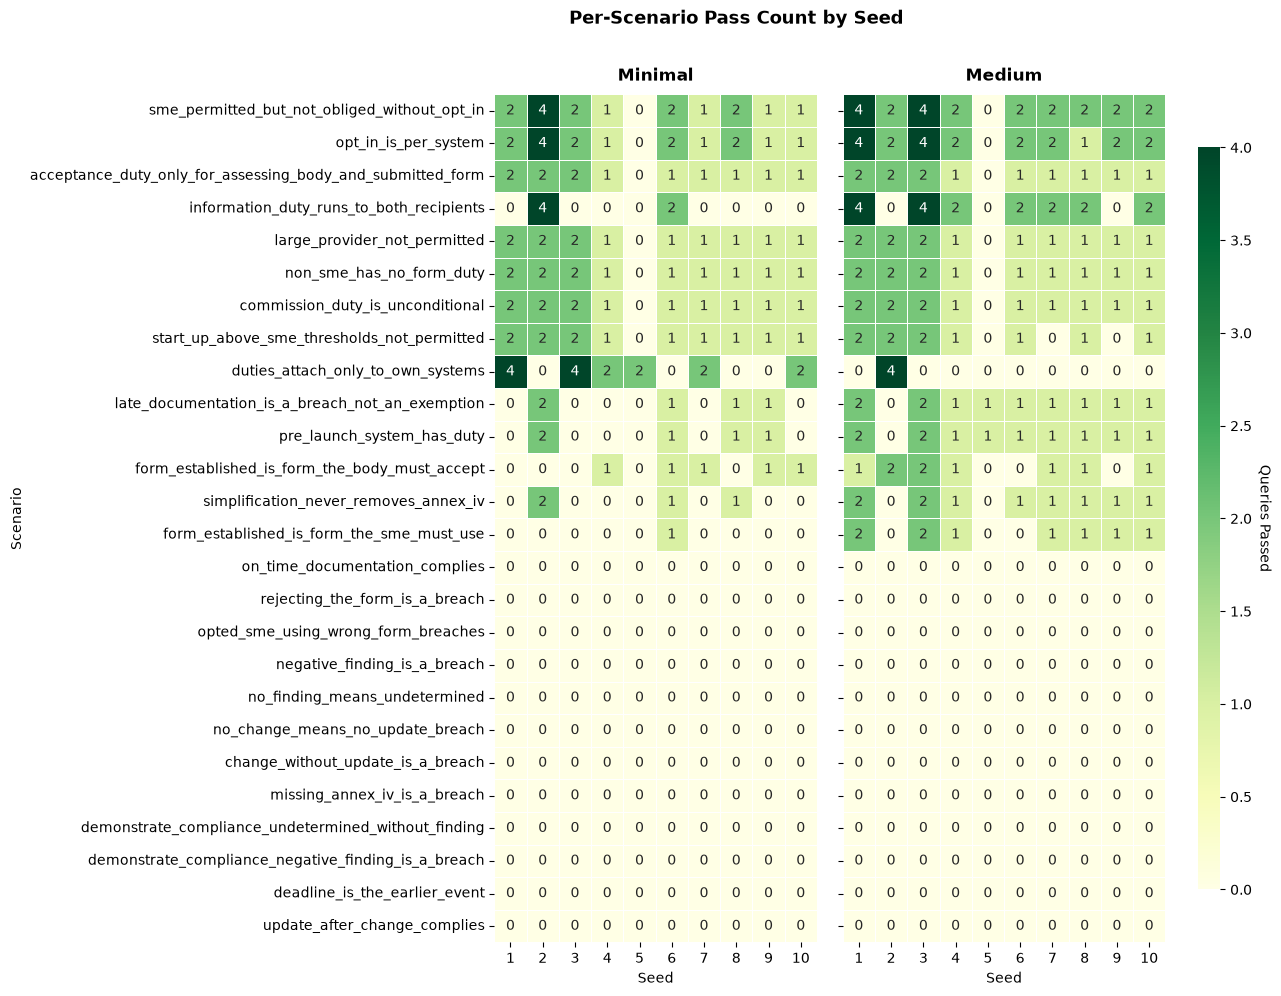

In [20]:
def build_pivot(df: pd.DataFrame, mode: str = "query_pass") -> pd.DataFrame:
    """
    Build a (scenario x seed) matrix.
    
    mode="query_pass"    -> count of passing queries per (scenario, seed)
    mode="scenario_pass" -> 1/0 whether the scenario passed for that seed
    """
    if mode == "query_pass":
        # Adjust the verdict string if your CSV uses "correct" or "ok" instead of "pass"
        passed = df["verdict"].str.lower().isin(["correct"])
        agg = df.assign(passed=passed).groupby(["scenario", "seed"])["passed"].sum()
    elif mode == "scenario_pass":
        # scenario_pass is repeated per query_idx, so take first() per (scenario, seed)
        agg = (
            df.groupby(["scenario", "seed"])["scenario_pass"]
            .first()
            .astype(int)
        )
    else:
        raise ValueError("mode must be 'query_pass' or 'scenario_pass'")

    return agg.unstack(fill_value=0)


# Switch to mode="scenario_pass" if you want 0/1 scenario passes instead of query counts
MODE = "query_pass"

piv_min = build_pivot(df_min, mode=MODE)
piv_med = build_pivot(df_med, mode=MODE)

# --- 2. Align scenarios & seeds, and sort to surface the 3 bins ---
all_scenarios = piv_min.index.union(piv_med.index)
all_seeds = sorted(piv_min.columns.union(piv_med.columns))

piv_min = piv_min.reindex(index=all_scenarios, columns=all_seeds, fill_value=0)
piv_med = piv_med.reindex(index=all_scenarios, columns=all_seeds, fill_value=0)

# Sort by combined pass count (descending) so always-pass, partial, and always-fail group together
sort_order = (piv_min.sum(axis=1) + piv_med.sum(axis=1)).sort_values(ascending=False).index
piv_min = piv_min.loc[sort_order]
piv_med = piv_med.loc[sort_order]

# --- 3. Plot side-by-side heatmaps ---
vmax = max(piv_min.values.max(), piv_med.values.max())
n_scenarios = len(sort_order)
fig_height = max(4.5, 0.35 * n_scenarios + 1.5)

fig, axes = plt.subplots(
    1, 2,
    figsize=(11, fig_height),
    sharey=True,
    gridspec_kw={"wspace": 0.08}
)

# Colorbar axis on the right
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])

heatmap_kwargs = dict(
    cmap="YlGn",          # Clean sequential palette; works well in print
    vmin=0,
    vmax=vmax,
    annot=True,
    fmt="d",
    linewidths=0.5,
    linecolor="white",
    cbar_ax=cbar_ax,
)

sns.heatmap(piv_min, ax=axes[0], cbar=False, **heatmap_kwargs)
sns.heatmap(piv_med, ax=axes[1], cbar=True, **heatmap_kwargs)

axes[0].set_title("Minimal", fontsize=12, fontweight="bold", pad=10)
axes[1].set_title("Medium", fontsize=12, fontweight="bold", pad=10)

axes[0].set_xlabel("Seed", fontsize=10)
axes[1].set_xlabel("Seed", fontsize=10)
axes[0].set_ylabel("Scenario", fontsize=10)
axes[1].set_ylabel("")

cbar_label = "Queries Passed" if MODE == "query_pass" else "Scenario Pass (0/1)"
cbar_ax.set_ylabel(cbar_label, fontsize=10, rotation=270, labelpad=14)

fig.suptitle("Per-Scenario Pass Count by Seed", fontsize=13, fontweight="bold", y=0.98)
fig.subplots_adjust(left=0.28, right=0.89, top=0.90, bottom=0.10)

# --- 4. Save for report ---
plt.savefig("scenario_pass_heatmap.png", dpi=300, bbox_inches="tight")
plt.savefig("scenario_pass_heatmap.pdf", bbox_inches="tight")
plt.show()

As we move to higher seeds pass numbers tend to go down, this is worth looking into.

## 3. Outputs

### 3.1 Pass count against completion tokens and cost per output

Question: do the extra scenarios that medium reasoning passes come with the extra tokens it writes, or is the gap between the two levels a step that more tokens *within* a level do not buy? If pass count rises with tokens inside a level, "think more" is a lever. If it only differs between levels, the lever is telling the model what to write.

`outputs.csv` has one row per generated module. Scenario columns (`scn_llm_*`) exist only for `art_11_par_1`, the one text with a suite. `completion_tokens` includes reasoning tokens for the medium arm; `reasoning_tokens` is the reasoning share, so `completion_tokens - reasoning_tokens` is the length of the Prolog actually written.

In [ ]:
df_out = pd.read_csv("./out_paragraphs/csv/outputs.csv")
df_out = df_out[df_out["model"].isin(["astra", "astra-medium"])].copy()
df_out["reasoning_tokens"] = df_out["reasoning_tokens"].fillna(0)
df_out["prolog_tokens"] = df_out["completion_tokens"] - df_out["reasoning_tokens"]
df_out["level"] = df_out["model"].map({"astra": "minimal", "astra-medium": "medium"})

# the scored subset: Article 11(1), LLM adapters
df_scn = df_out[df_out["text"] == "art_11_par_1"].dropna(subset=["scn_llm_passed"]).copy()
df_scn["scn_llm_passed"] = df_scn["scn_llm_passed"].astype(int)
df_scn["cost_per_passed"] = df_scn["cost_usd"] / df_scn["scn_llm_passed"].replace(0, np.nan)
df_scn[["model", "seed", "gate_pass", "clauses", "completion_tokens", "reasoning_tokens", "prolog_tokens",
        "cost_usd", "scn_llm_passed", "scn_llm_unanswerable"]].sort_values(["model", "seed"])

In [ ]:
# per level: what medium buys, on average
summary = (df_scn.groupby("level")
           .agg(outputs=("seed", "count"),
                gate_pass_rate=("gate_pass", "mean"),
                passed_mean=("scn_llm_passed", "mean"),
                passed_min=("scn_llm_passed", "min"),
                passed_max=("scn_llm_passed", "max"),
                completion_tokens=("completion_tokens", "mean"),
                reasoning_tokens=("reasoning_tokens", "mean"),
                prolog_tokens=("prolog_tokens", "mean"),
                cost_usd=("cost_usd", "mean"),
                cost_per_passed=("cost_per_passed", "mean"))
           .round(3))
summary

In [ ]:
# pass count against tokens and against cost. Hollow markers = output failed the gate (did not load).
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, x, label in zip(axes,
                        ["completion_tokens", "prolog_tokens", "cost_usd"],
                        ["completion tokens (incl. reasoning)", "Prolog tokens (completion - reasoning)", "cost per output, USD"]):
    sns.scatterplot(data=df_scn, x=x, y="scn_llm_passed", hue="level", style="gate_pass",
                    markers={True: "o", False: "X"}, s=80, ax=ax)
    for _, r in df_scn.iterrows():
        ax.annotate(int(r["seed"]), (r[x], r["scn_llm_passed"]), textcoords="offset points", xytext=(5, 3), fontsize=8)
    ax.set_xlabel(label)
    ax.set_ylabel("scenarios passed (of 26)")
    ax.grid(alpha=0.3)
axes[0].set_title("Article 11(1), 10 seeds per level")
plt.tight_layout()

In [ ]:
# within-level association (gate-passing outputs only, so the two non-loading seeds do not drive it).
# Spearman rho = Pearson correlation of the ranks (no scipy needed). With n = 9 per level, |rho| below ~0.6 is noise.
ok = df_scn[df_scn["gate_pass"] == True]
rows = []
for level, g in list(ok.groupby("level")) + [("both levels pooled", ok)]:
    for x in ["completion_tokens", "prolog_tokens", "reasoning_tokens", "cost_usd", "clauses"]:
        rho = g[x].rank().corr(g["scn_llm_passed"].rank())
        rows.append({"level": level, "x": x, "n": len(g), "spearman_rho": round(rho, 2) if pd.notna(rho) else None})
pd.DataFrame(rows).pivot(index="x", columns="level", values="spearman_rho")


In [ ]:
# cost per passed scenario, per output. Outputs that pass nothing have no value here and are dropped.
fig, ax = plt.subplots(figsize=(6, 4))
sns.stripplot(data=df_scn.dropna(subset=["cost_per_passed"]), x="level", y="cost_per_passed", hue="level",
              size=8, jitter=0.15, legend=False, ax=ax)
sns.pointplot(data=df_scn.dropna(subset=["cost_per_passed"]), x="level", y="cost_per_passed",
              color="black", errorbar=None, markers="_", linestyles="", ax=ax)
ax.set_ylabel("USD per passed scenario")
ax.set_xlabel("")
ax.set_title("Cost per passed scenario (black = mean)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()

In [ ]:
# the same tokens and cost over all five texts, to see whether the 1.7x factor holds beyond Article 11(1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=df_out, x="text", y="completion_tokens", hue="level", ax=axes[0])
axes[0].set_title("completion tokens per output, by text")
axes[0].tick_params(axis="x", rotation=20)
sns.boxplot(data=df_out, x="text", y="cost_usd", hue="level", ax=axes[1])
axes[1].set_title("cost per output (USD), by text")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()

ratio = (df_out.groupby(["text", "level"])[["completion_tokens", "cost_usd"]].mean()
         .unstack("level"))
ratio["tokens_medium_over_minimal"] = ratio[("completion_tokens", "medium")] / ratio[("completion_tokens", "minimal")]
ratio["cost_medium_over_minimal"] = ratio[("cost_usd", "medium")] / ratio[("cost_usd", "minimal")]
ratio[["tokens_medium_over_minimal", "cost_medium_over_minimal"]].round(2)

How to read this:

- The **gap between the two clouds** is the between-level effect: medium passes more at every token count it reaches.
- The **slope inside one cloud** (and the Spearman rho above) is the within-level effect. A rho near zero inside a level means that longer or costlier outputs of the same level do not pass more, so the gain comes from the reasoning setting, not from length.
- The two **X markers** are the seed-5 outputs that did not load (5 clauses each). They are the shortest outputs and score 0 or 1, so leave them out of any correlation: they are gate failures, not short good modules.
- `prolog_tokens` separates "wrote more Prolog" from "reasoned more". If pass count tracks `prolog_tokens` but not `reasoning_tokens`, the value is in the output length; if the reverse, in the reasoning.

Within a level, longer or costlier outputs pass no more, so output length is not a lever. Between levels, medium passes more, so the reasoning setting is a lever,
  but what it buys is consistency on things the model already encodes: the form identity, the opt-in, the recipients. The norms at zero on all 20 outputs, breach, deadlines,
  update, status, are untouched by either. For those the only lever left is telling the model what to write. So: reasoning for stability, prompt for structure.

### 3.2 Direction of error: false positives against missed, per model

A wrong answer has a direction. A **false positive** is a duty or breach the module derives that the text does not impose (expected false, module says true): a system flagged non-compliant, or a bystander burdened with someone else's duty. A **missed** answer is a duty or breach the module fails to derive (expected true, module says false): a non-compliant system that passes. **Unanswerable** is a query the module cannot express at all. For a legal tool the direction matters more than the count: a module that misses is silent where it should speak, a module that invents accuses where it should be silent. The study outputs, all seven models at seeds 1 to 3 plus the 10-seed Astra arms, go in one scatter.

In [27]:
# every scored output of Article 11(1): the 7 study models (seeds 1-3, LLM adapters) and the 10-seed Astra arms
df_err = pd.read_csv("./out_paragraphs/csv/outputs.csv")
df_err = df_err[(df_err["text"] == "art_11_par_1")].dropna(subset=["scn_llm_passed"]).copy()
for c in ["scn_llm_passed", "scn_llm_false_positive", "scn_llm_missed", "scn_llm_unanswerable"]:
    df_err[c] = df_err[c].astype(int)
df_err["answered_wrong"] = df_err["scn_llm_false_positive"] + df_err["scn_llm_missed"]
# share of wrong answers that are false positives: 1 = invents, 0 = misses, NaN = answered nothing wrong
df_err["fp_share"] = df_err["scn_llm_false_positive"] / df_err["answered_wrong"].replace(0, np.nan)
df_err.groupby("model")[["scn_llm_passed", "scn_llm_false_positive", "scn_llm_missed", "scn_llm_unanswerable"]].mean().round(2)

,scn_llm_passed,scn_llm_false_positive,scn_llm_missed,scn_llm_unanswerable
model,,,,
astra,5.90,1.70,5.00,16.10
astra-medium,7.80,3.00,1.20,15.70
deepseek,3.33,0.33,5.33,20.67
gemini,5.33,3.67,4.00,15.00
kimi,6.00,3.00,4.00,14.67
mistral,4.00,2.00,7.00,15.33
opus,6.67,2.67,2.67,16.00
qwen,4.67,4.67,3.00,15.33


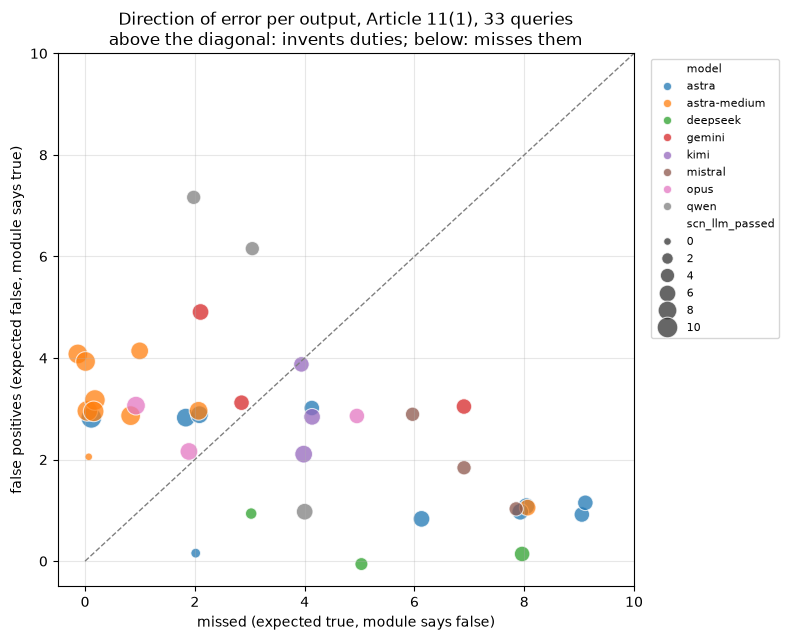

In [28]:
# one point per output; the diagonal is "as many invented as missed". Point size = scenarios passed.
fig, ax = plt.subplots(figsize=(8, 6.5))
jit = np.random.default_rng(0).uniform(-0.18, 0.18, size=(len(df_err), 2))   # integers overlap; nudge
sns.scatterplot(data=df_err.assign(x=df_err["scn_llm_missed"] + jit[:, 0], y=df_err["scn_llm_false_positive"] + jit[:, 1]),
                x="x", y="y", hue="model", size="scn_llm_passed", sizes=(30, 220), alpha=0.75, ax=ax)
lim = max(df_err["scn_llm_missed"].max(), df_err["scn_llm_false_positive"].max()) + 1
ax.plot([0, lim], [0, lim], ls="--", c="grey", lw=1)
ax.set_xlabel("missed (expected true, module says false)")
ax.set_ylabel("false positives (expected false, module says true)")
ax.set_title("Direction of error per output, Article 11(1), 33 queries\nabove the diagonal: invents duties; below: misses them")
ax.set_xlim(-0.5, lim); ax.set_ylim(-0.5, lim)
ax.grid(alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()

,model,fp,fp_sd,miss,miss_sd,unans,n,fp_share
1,astra-medium,3.00,0.94,1.20,2.49,15.70,10,0.83
7,qwen,4.67,3.21,3.00,1.00,15.33,3,0.55
6,opus,2.67,0.58,2.67,2.08,16.00,3,0.54
3,gemini,3.67,1.15,4.00,2.65,15.00,3,0.50
4,kimi,3.00,1.00,4.00,0.00,14.67,3,0.42
0,astra,1.70,1.16,5.00,3.40,16.10,10,0.32
5,mistral,2.00,1.00,7.00,1.00,15.33,3,0.22
2,deepseek,0.33,0.58,5.33,2.52,20.67,3,0.08


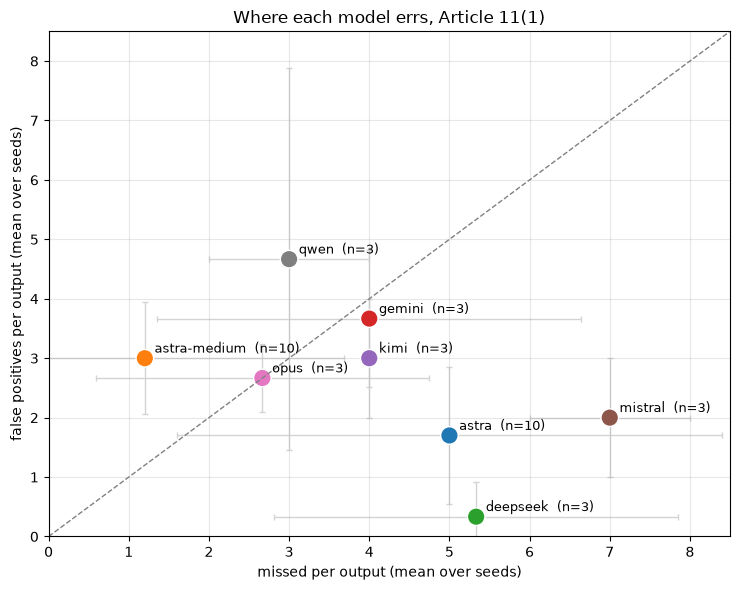

In [29]:
# per model: mean false positives against mean missed, with the spread over seeds as error bars
g = df_err.groupby("model").agg(fp=("scn_llm_false_positive", "mean"), fp_sd=("scn_llm_false_positive", "std"),
                                miss=("scn_llm_missed", "mean"), miss_sd=("scn_llm_missed", "std"),
                                unans=("scn_llm_unanswerable", "mean"), n=("seed", "count"),
                                fp_share=("fp_share", "mean")).reset_index()
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.errorbar(g["miss"], g["fp"], xerr=g["miss_sd"], yerr=g["fp_sd"], fmt="none", ecolor="lightgrey", elinewidth=1, capsize=2, zorder=1)
sns.scatterplot(data=g, x="miss", y="fp", hue="model", s=160, ax=ax, zorder=2, legend=False)
for _, r in g.iterrows():
    ax.annotate(f"{r['model']}  (n={int(r['n'])})", (r["miss"], r["fp"]), textcoords="offset points", xytext=(7, 4), fontsize=9)
lim = max(g["miss"].max(), g["fp"].max()) + 1.5
ax.plot([0, lim], [0, lim], ls="--", c="grey", lw=1)
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("missed per output (mean over seeds)")
ax.set_ylabel("false positives per output (mean over seeds)")
ax.set_title("Where each model errs, Article 11(1)")
ax.grid(alpha=0.3)
plt.tight_layout()
g.round(2).sort_values("fp_share", ascending=False)

verdict,correct,false_positive,missed,unanswerable
model,,,,
astra-medium,0.40,0.09,0.04,0.48
opus,0.35,0.08,0.08,0.48
kimi,0.34,0.09,0.12,0.44
gemini,0.31,0.11,0.12,0.45
astra,0.31,0.05,0.15,0.49
qwen,0.30,0.14,0.09,0.46
mistral,0.26,0.06,0.21,0.46
deepseek,0.20,0.01,0.16,0.63


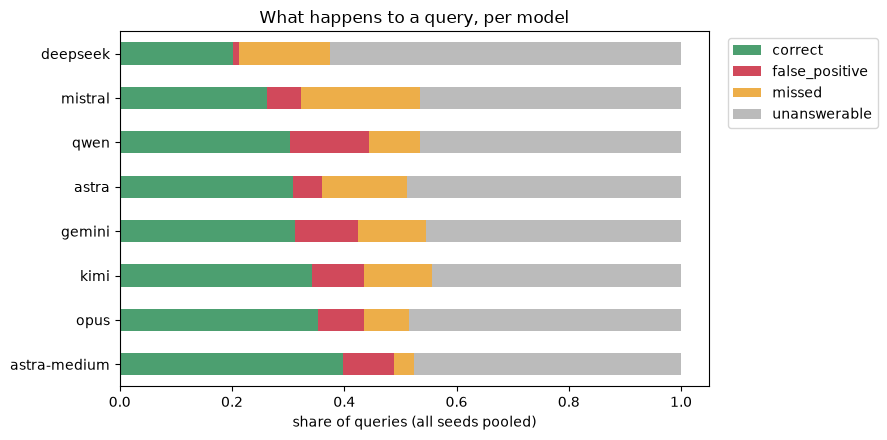

In [30]:
# composition of all 33 answers per model: correct / false positive / missed / unanswerable, as shares
df_q = pd.read_csv("./out_paragraphs/csv/scenario_queries.csv")
df_q = df_q[(df_q["text"] == "art_11_par_1") & (df_q["adapter"] == "llm")]
comp = (df_q.groupby(["model", "verdict"]).size().unstack(fill_value=0))
comp = comp.div(comp.sum(axis=1), axis=0)[["correct", "false_positive", "missed", "unanswerable"]]
comp = comp.sort_values("correct", ascending=False)
ax = comp.plot(kind="barh", stacked=True, figsize=(9, 4.5),
               color={"correct": "#4c9f70", "false_positive": "#d1495b", "missed": "#edae49", "unanswerable": "#bbbbbb"})
ax.set_xlabel("share of queries (all seeds pooled)")
ax.set_ylabel("")
ax.set_title("What happens to a query, per model")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
comp.round(2)

In [31]:
# which scenarios produce the false positives? If one scenario dominates, the direction is a suite property, not a model one.
fp_by = (df_q[df_q["verdict"] == "false_positive"].groupby(["scenario", "model"]).size().unstack(fill_value=0))
fp_by["total"] = fp_by.sum(axis=1)
fp_by.sort_values("total", ascending=False)

model,astra,astra-medium,deepseek,gemini,kimi,mistral,opus,qwen,total
scenario,,,,,,,,,
duties_attach_only_to_own_systems,8,18,0,2,2,0,2,4,36
acceptance_duty_only_for_assessing_body_and_submitted_form,9,9,1,3,1,1,3,2,29
start_up_above_sme_thresholds_not_permitted,0,2,0,3,3,3,1,3,15
opt_in_is_per_system,0,1,0,3,2,2,2,2,12
sme_permitted_but_not_obliged_without_opt_in,0,0,0,0,1,0,0,1,2
large_provider_not_permitted,0,0,0,0,0,0,0,1,1
non_sme_has_no_form_duty,0,0,0,0,0,0,0,1,1
